# XGBoost Time-to-Event Regressor

Predict survival time (days) using XGBoost regression.

In [1]:
# Cell 1: Import libraries
import sys
import os
sys.path.append(os.path.abspath('../../'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRegressor
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, median_absolute_error

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
dataset = pd.read_csv("../data/data.csv")

diagnosis_variables = []

with open("../data/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

In [4]:
# Prepare data
data_x = survival_dataset[feature_columns]
data_y_time = survival_dataset['Survival days'].values
data_y_event = survival_dataset['Regional LN recurrence'].values

print(f"Features shape: {data_x.shape}")
print(f"Target (Survival days) - Mean: {data_y_time.mean():.0f}, Median: {np.median(data_y_time):.0f}")
print(f"Event rate: {data_y_event.mean():.2%}")

Features shape: (3230, 45)
Target (Survival days) - Mean: 1254, Median: 1342
Event rate: 0.93%


In [5]:
# Train/Test Split (hold out test set for final evaluation)
sgkf = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=data_y_event)

train_index, test_index = next(cv)
x_train = data_x.iloc[train_index]
y_train = data_y_time[train_index]
event_train = data_y_event[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y_time[test_index]
event_test = data_y_event[test_index]

print(f"Training set: {len(x_train)} samples (events: {event_train.sum()})")
print(f"Test set: {len(x_test)} samples (events: {event_test.sum()})")

Training set: 2584 samples (events: 24.0)
Test set: 646 samples (events: 6.0)


In [51]:
# Cell 7: Grid Search for Best Hyperparameters
from itertools import product

print("=== Grid Search for XGBoost Hyperparameters ===\n")

# Define parameter grid (keeping it manageable for runtime)
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'min_child_weight': [1, 3, 5]
}

# Generate all combinations
param_names = list(param_grid.keys())
param_values = list(param_grid.values())
param_combinations = list(product(*param_values))

print(f"Testing {len(param_combinations)} parameter combinations")
print(f"Parameters: {param_names}\n")

# Use 4-fold CV on training data for faster grid search
n_cv_splits = 12
cv_splitter = StratifiedKFold(n_splits=n_cv_splits, shuffle=True, random_state=42)

results = []

for idx, param_combo in enumerate(param_combinations):
    params = dict(zip(param_names, param_combo))
    params['random_state'] = 42
    params['n_jobs'] = -1
    
    # Track fold metrics
    fold_mae = []
    fold_rmse = []
    fold_r2 = []
    
    # Perform CV
    for fold_idx, (train_idx, val_idx) in enumerate(cv_splitter.split(x_train, event_train)):
        X_tr = x_train.iloc[train_idx].values
        X_val = x_train.iloc[val_idx].values
        y_tr = y_train[train_idx]
        y_val = y_train[val_idx]
        
        # Train model
        model = XGBRegressor(**params)
        model.fit(X_tr, y_tr)
        
        # Predict
        y_pred = model.predict(X_val)
        
        # Calculate metrics
        fold_mae.append(mean_absolute_error(y_val, y_pred))
        fold_rmse.append(np.sqrt(mean_squared_error(y_val, y_pred)))
        fold_r2.append(r2_score(y_val, y_pred))
    
    # Store results
    result = {
        'n_estimators': params['n_estimators'],
        'max_depth': params['max_depth'],
        'learning_rate': params['learning_rate'],
        'min_child_weight': params['min_child_weight'],
        'mae_mean': np.mean(fold_mae),
        'mae_std': np.std(fold_mae),
        'rmse_mean': np.mean(fold_rmse),
        'rmse_std': np.std(fold_rmse),
        'r2_mean': np.mean(fold_r2),
        'r2_std': np.std(fold_r2)
    }
    results.append(result)
    
    if (idx + 1) % 10 == 0:
        print(f"  Completed {idx + 1}/{len(param_combinations)} combinations...")

results_df = pd.DataFrame(results)
# Find best parameters based on MAE (lower is better)
best_idx_mae = results_df['mae_mean'].idxmin()
best_params_mae = results_df.loc[best_idx_mae]

# Find best parameters based on R² (higher is better)
best_idx_r2 = results_df['r2_mean'].idxmax()
best_params_r2 = results_df.loc[best_idx_r2]

print("\n=== Grid Search Results ===\n")
print("Best Parameters (by MAE):")
print(f"  n_estimators: {int(best_params_mae['n_estimators'])}")
print(f"  max_depth: {int(best_params_mae['max_depth'])}")
print(f"  learning_rate: {best_params_mae['learning_rate']}")
print(f"  min_child_weight: {int(best_params_mae['min_child_weight'])}")
print(f"  MAE: {best_params_mae['mae_mean']:.2f} ± {best_params_mae['mae_std']:.2f} days")
print(f"  RMSE: {best_params_mae['rmse_mean']:.2f} ± {best_params_mae['rmse_std']:.2f} days")
print(f"  R²: {best_params_mae['r2_mean']:.4f} ± {best_params_mae['r2_std']:.4f}")

print("\nBest Parameters (by R²):")
print(f"  n_estimators: {int(best_params_r2['n_estimators'])}")
print(f"  max_depth: {int(best_params_r2['max_depth'])}")
print(f"  learning_rate: {best_params_r2['learning_rate']}")
print(f"  min_child_weight: {int(best_params_r2['min_child_weight'])}")
print(f"  MAE: {best_params_r2['mae_mean']:.2f} ± {best_params_r2['mae_std']:.2f} days")
print(f"  RMSE: {best_params_r2['rmse_mean']:.2f} ± {best_params_r2['rmse_std']:.2f} days")
print(f"  R²: {best_params_r2['r2_mean']:.4f} ± {best_params_r2['r2_std']:.4f}")

# Display top 10 configurations
print("\n=== Top 10 Configurations (by MAE) ===")
top_10 = results_df.nsmallest(10, 'mae_mean')
print(top_10.to_string(index=False))

# Save grid search results
results_df.to_csv('xgboost_grid_search_results.csv', index=False)
print("\nGrid search results saved to 'xgboost_grid_search_results.csv'")

# Set best parameters for subsequent cells
best_model_params = {
    'n_estimators': int(best_params_mae['n_estimators']),
    'max_depth': int(best_params_mae['max_depth']),
    'learning_rate': float(best_params_mae['learning_rate']),
    'min_child_weight': int(best_params_mae['min_child_weight']),
    'random_state': 42,
    'n_jobs': -1
}

print(f"\nBest parameters stored in 'best_model_params' for use in subsequent cells")


=== Grid Search for XGBoost Hyperparameters ===

Testing 54 parameter combinations
Parameters: ['n_estimators', 'max_depth', 'learning_rate', 'min_child_weight']

  Completed 10/54 combinations...
  Completed 20/54 combinations...
  Completed 30/54 combinations...
  Completed 40/54 combinations...
  Completed 50/54 combinations...

=== Grid Search Results ===

Best Parameters (by MAE):
  n_estimators: 100
  max_depth: 7
  learning_rate: 0.1
  min_child_weight: 3
  MAE: 438.99 ± 22.92 days
  RMSE: 528.95 ± 22.47 days
  R²: 0.0963 ± 0.0849

Best Parameters (by R²):
  n_estimators: 100
  max_depth: 3
  learning_rate: 0.1
  min_child_weight: 1
  MAE: 445.41 ± 23.09 days
  RMSE: 517.16 ± 20.84 days
  R²: 0.1387 ± 0.0382

=== Top 10 Configurations (by MAE) ===
 n_estimators  max_depth  learning_rate  min_child_weight   mae_mean   mae_std  rmse_mean  rmse_std  r2_mean   r2_std
          100          7           0.10                 3 438.988339 22.919931 528.947149 22.473196 0.096325 0.084881

In [ ]:
# Cell 7b: Visualize Grid Search Results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. MAE by n_estimators
ax1 = axes[0, 0]
for lr in param_grid['learning_rate']:
    subset = results_df[results_df['learning_rate'] == lr]
    grouped = subset.groupby('n_estimators')['mae_mean'].mean()
    ax1.plot(grouped.index, grouped.values, marker='o', label=f'LR={lr}', linewidth=2)
ax1.set_xlabel('n_estimators', fontsize=11)
ax1.set_ylabel('MAE (days)', fontsize=11)
ax1.set_title('MAE vs n_estimators (by learning rate)', fontsize=12)
ax1.legend()
ax1.grid(alpha=0.3)

# 2. MAE by max_depth
ax2 = axes[0, 1]
for lr in param_grid['learning_rate']:
    subset = results_df[results_df['learning_rate'] == lr]
    grouped = subset.groupby('max_depth')['mae_mean'].mean()
    ax2.plot(grouped.index, grouped.values, marker='s', label=f'LR={lr}', linewidth=2)
ax2.set_xlabel('max_depth', fontsize=11)
ax2.set_ylabel('MAE (days)', fontsize=11)
ax2.set_title('MAE vs max_depth (by learning rate)', fontsize=12)
ax2.legend()
ax2.grid(alpha=0.3)

# 3. R² by n_estimators
ax3 = axes[1, 0]
for lr in param_grid['learning_rate']:
    subset = results_df[results_df['learning_rate'] == lr]
    grouped = subset.groupby('n_estimators')['r2_mean'].mean()
    ax3.plot(grouped.index, grouped.values, marker='o', label=f'LR={lr}', linewidth=2)
ax3.set_xlabel('n_estimators', fontsize=11)
ax3.set_ylabel('R²', fontsize=11)
ax3.set_title('R² vs n_estimators (by learning rate)', fontsize=12)
ax3.legend()
ax3.grid(alpha=0.3)

# 4. Heatmap: MAE by max_depth and min_child_weight
ax4 = axes[1, 1]
pivot = results_df.groupby(['max_depth', 'min_child_weight'])['mae_mean'].mean().reset_index()
pivot_table = pivot.pivot(index='max_depth', columns='min_child_weight', values='mae_mean')
im = ax4.imshow(pivot_table.values, cmap='RdYlGn_r', aspect='auto')
ax4.set_xticks(range(len(pivot_table.columns)))
ax4.set_yticks(range(len(pivot_table.index)))
ax4.set_xticklabels(pivot_table.columns)
ax4.set_yticklabels(pivot_table.index)
ax4.set_xlabel('min_child_weight', fontsize=11)
ax4.set_ylabel('max_depth', fontsize=11)
ax4.set_title('MAE Heatmap: max_depth vs min_child_weight', fontsize=12)
plt.colorbar(im, ax=ax4, label='MAE (days)')

# Add values to heatmap
for i in range(len(pivot_table.index)):
    for j in range(len(pivot_table.columns)):
        text = ax4.text(j, i, f'{pivot_table.values[i, j]:.1f}',
                       ha="center", va="center", color="black", fontsize=9)

plt.tight_layout()
plt.show()

print("Grid search visualizations complete")


In [ ]:
# Cell 8: Collect Validation Predictions via Repeated CV (using best parameters)
from sklearn.model_selection import RepeatedStratifiedKFold

# Use best parameters from grid search (or default if grid search not run)
if 'best_model_params' not in locals():
    print("Warning: Using default parameters. Run grid search cell first for optimal results.")
    model_params = {
        'n_estimators': 200,
        'max_depth': 5,
        'learning_rate': 0.1,
        'min_child_weight': 3,
        'random_state': 42,
        'n_jobs': -1
    }
else:
    model_params = best_model_params.copy()
    print("Using best parameters from grid search:")

print(f"Model params: {model_params}")
print("\nCollecting validation predictions via Repeated Stratified CV...")

# Store all validation predictions
all_predictions = []

n_splits = 12
n_repeats = 1
rskf = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats, random_state=42)

# Use training data for CV
X_array = x_train.values
y_time_array = y_train
event_array = event_train

for fold_idx, (train_idx, val_idx) in enumerate(rskf.split(X_array, event_array)):
    repeat = fold_idx // n_splits + 1
    fold = fold_idx % n_splits + 1
    
    X_tr, X_val = X_array[train_idx], X_array[val_idx]
    y_tr, y_val = y_time_array[train_idx], y_time_array[val_idx]
    event_val_fold = event_array[val_idx]
    
    # Train model
    model = XGBRegressor(**model_params)
    model.fit(X_tr, y_tr)
    
    # Predict on validation set
    y_pred = model.predict(X_val)
    
    # Store predictions with metadata
    for i, idx in enumerate(val_idx):
        all_predictions.append({
            'sample_idx': idx,
            'repeat': repeat,
            'fold': fold,
            'actual_time': y_val[i],
            'predicted_time': y_pred[i],
            'event': event_val_fold[i]
        })
    
    if fold_idx % n_splits == 0:
        print(f"  Repeat {repeat}/{n_repeats} completed...")

# Create predictions dataframe
predictions_df = pd.DataFrame(all_predictions)

# Aggregate predictions per sample (average across repeats)
agg_predictions = predictions_df.groupby('sample_idx').agg({
    'actual_time': 'first',
    'predicted_time': 'mean',
    'event': 'first'
}).reset_index()

print(f"\nTotal predictions collected: {len(predictions_df)}")
print(f"Unique samples: {len(agg_predictions)}")
print(f"Predictions per sample: {n_repeats} (averaged)")

Model params: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'min_child_weight': 3, 'random_state': 42, 'n_jobs': -1}
  Repeat 1/1 completed...

Total predictions collected: 2584
Unique samples: 2584
Predictions per sample: 1 (averaged)


In [46]:
# Cell 6: Evaluate Validation Predictions
def evaluate_regression(y_true, y_pred, set_name=""):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    med_ae = median_absolute_error(y_true, y_pred)
    
    print(f"{set_name} Metrics:")
    print(f"  RMSE: {rmse:.2f} days")
    print(f"  MAE: {mae:.2f} days")
    print(f"  Median AE: {med_ae:.2f} days")
    print(f"  R²: {r2:.4f}")
    return {'RMSE': rmse, 'MAE': mae, 'MedianAE': med_ae, 'R2': r2}

# Extract arrays for evaluation
y_actual = agg_predictions['actual_time'].values
y_pred_val = agg_predictions['predicted_time'].values
event_val = agg_predictions['event'].values

print("=== XGBoost Regressor - Validation Results ===\n")
val_metrics = evaluate_regression(y_actual, y_pred_val, "Validation (CV)")

=== XGBoost Regressor - Validation Results ===

Validation (CV) Metrics:
  RMSE: 529.51 days
  MAE: 441.57 days
  Median AE: 411.61 days
  R²: 0.1060


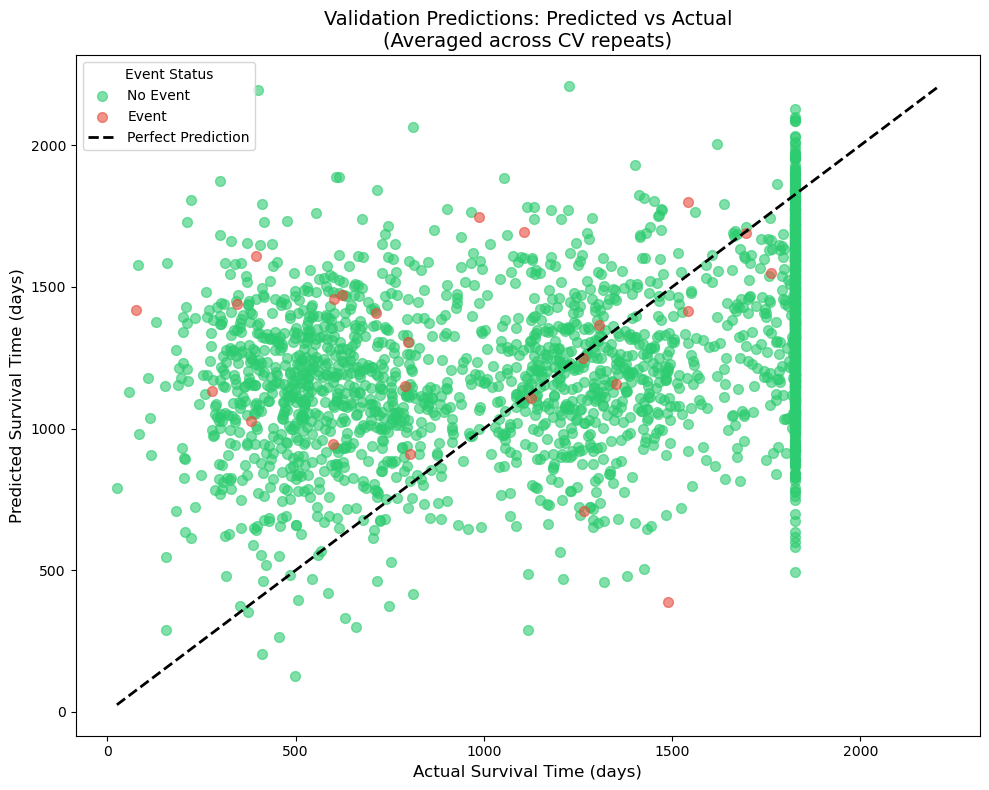


Correlation: Pearson r = 0.3627, Spearman ρ = 0.3660


In [47]:
# Cell 7: Validation Predictions - Scatter Plot (separated by event status)
fig, ax = plt.subplots(figsize=(10, 8))

colors = ['#2ecc71', '#e74c3c']
labels = ['No Event', 'Event']

for i, (color, label) in enumerate(zip(colors, labels)):
    mask = event_val == i
    ax.scatter(y_actual[mask], y_pred_val[mask], c=color, label=label, alpha=0.6, s=50)

# Perfect prediction line
min_val = min(y_actual.min(), y_pred_val.min())
max_val = max(y_actual.max(), y_pred_val.max())
ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=2, label='Perfect Prediction')

ax.set_xlabel('Actual Survival Time (days)', fontsize=12)
ax.set_ylabel('Predicted Survival Time (days)', fontsize=12)
ax.set_title('Validation Predictions: Predicted vs Actual\n(Averaged across CV repeats)', fontsize=14)
ax.legend(title='Event Status')

plt.tight_layout()
plt.show()

# Print correlation
from scipy.stats import pearsonr, spearmanr
pearson_r, _ = pearsonr(y_actual, y_pred_val)
spearman_r, _ = spearmanr(y_actual, y_pred_val)
print(f"\nCorrelation: Pearson r = {pearson_r:.4f}, Spearman ρ = {spearman_r:.4f}")

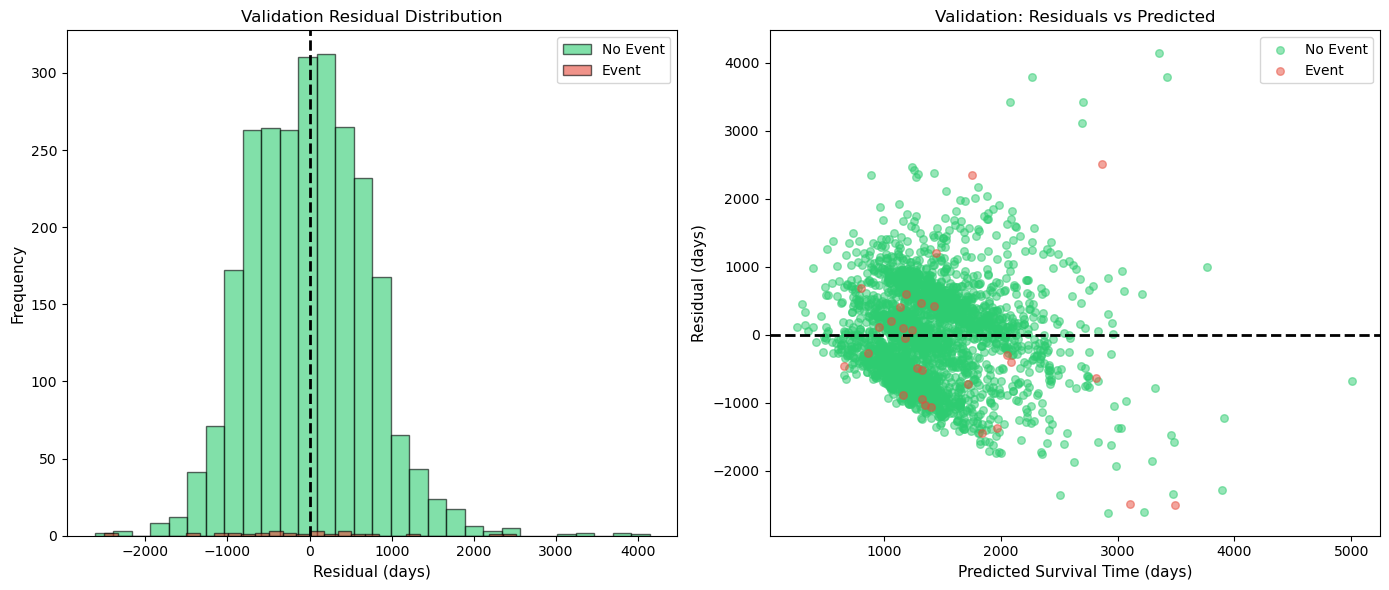


Residual Statistics (Validation):
  Mean residual: -4.51 days
  Std residual: 719.76 days
  Event samples - Mean residual: -221.79 days
  No Event samples - Mean residual: -2.04 days


In [35]:
# Cell 8: Residual Analysis - Validation Predictions (separated by event status)
residuals_val = y_actual - y_pred_val

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Residual distribution
ax1 = axes[0]
for i, (color, label) in enumerate(zip(colors, labels)):
    mask = event_val == i
    ax1.hist(residuals_val[mask], bins=30, alpha=0.6, color=color, label=label, edgecolor='black')
ax1.axvline(x=0, color='black', linestyle='--', linewidth=2)
ax1.set_xlabel('Residual (days)', fontsize=11)
ax1.set_ylabel('Frequency', fontsize=11)
ax1.set_title('Validation Residual Distribution', fontsize=12)
ax1.legend()

# Residual vs Predicted
ax2 = axes[1]
for i, (color, label) in enumerate(zip(colors, labels)):
    mask = event_val == i
    ax2.scatter(y_pred_val[mask], residuals_val[mask], c=color, label=label, alpha=0.5, s=30)
ax2.axhline(y=0, color='black', linestyle='--', linewidth=2)
ax2.set_xlabel('Predicted Survival Time (days)', fontsize=11)
ax2.set_ylabel('Residual (days)', fontsize=11)
ax2.set_title('Validation: Residuals vs Predicted', fontsize=12)
ax2.legend()

plt.tight_layout()
plt.show()

# Print residual statistics
print("\nResidual Statistics (Validation):")
print(f"  Mean residual: {residuals_val.mean():.2f} days")
print(f"  Std residual: {residuals_val.std():.2f} days")
print(f"  Event samples - Mean residual: {residuals_val[event_val==1].mean():.2f} days")
print(f"  No Event samples - Mean residual: {residuals_val[event_val==0].mean():.2f} days")

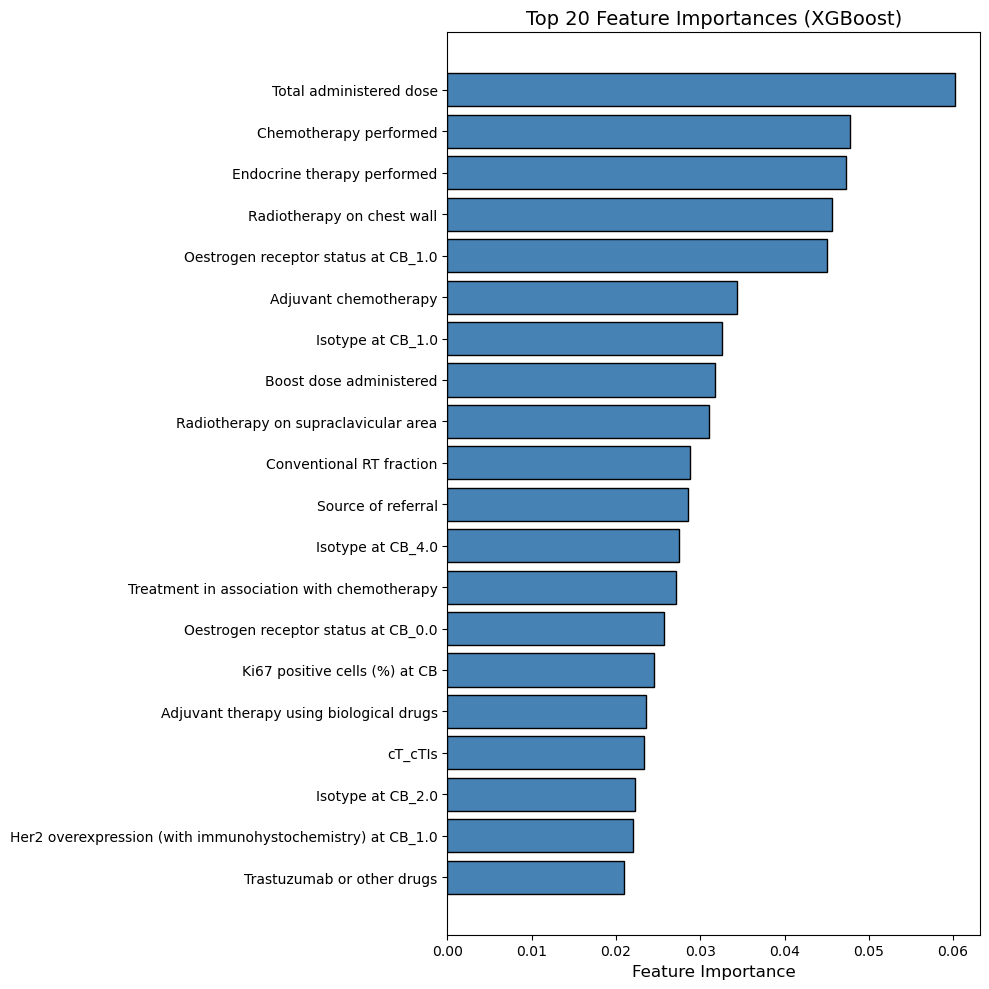


Top 10 Most Important Features:
  Total administered dose: 0.0602
  Chemotherapy performed: 0.0477
  Endocrine therapy performed: 0.0473
  Radiotherapy on chest wall: 0.0457
  Oestrogen receptor status at CB_1.0: 0.0451
  Adjuvant chemotherapy: 0.0343
  Isotype at CB_1.0: 0.0326
  Boost dose administered: 0.0318
  Radiotherapy on supraclavicular area: 0.0311
  Conventional RT fraction: 0.0288


In [ ]:
# Cell 10: Feature Importance (train on full training data with best parameters)
if 'best_model_params' in locals():
    final_model = XGBRegressor(**best_model_params)
else:
    final_model = XGBRegressor(**model_params)

final_model.fit(x_train, y_train)

importances = final_model.feature_importances_
importance_df = pd.DataFrame({
    'Feature': feature_columns,
    'Importance': importances
}).sort_values('Importance', ascending=False)

# Plot top 20 features
fig, ax = plt.subplots(figsize=(10, 10))
top_n = 20
top_features = importance_df.head(top_n)

ax.barh(range(top_n), top_features['Importance'].values, color='steelblue', edgecolor='black')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_features['Feature'].values)
ax.invert_yaxis()
ax.set_xlabel('Feature Importance', fontsize=12)
ax.set_title(f'Top {top_n} Feature Importances (XGBoost)', fontsize=14)

plt.tight_layout()
plt.show()

# Print feature importance
print(f"\nTop 10 Most Important Features:")
for idx, row in importance_df.head(10).iterrows():
    print(f"  {row['Feature']}: {row['Importance']:.4f}")


In [37]:
# Cell 10: Performance by Event Status (Validation Predictions)
print("=== Performance by Event Status (Validation) ===\n")

for event_value, label in [(0, 'No Event'), (1, 'Event')]:
    mask = event_val == event_value
    if mask.sum() > 0:
        y_true_subset = y_actual[mask]
        y_pred_subset = y_pred_val[mask]
        
        rmse = np.sqrt(mean_squared_error(y_true_subset, y_pred_subset))
        mae = mean_absolute_error(y_true_subset, y_pred_subset)
        r2 = r2_score(y_true_subset, y_pred_subset) if len(y_true_subset) > 1 else np.nan
        med_ae = median_absolute_error(y_true_subset, y_pred_subset)
        
        print(f"{label} (n={mask.sum()}):")
        print(f"  Actual time - Mean: {y_true_subset.mean():.0f}, Median: {np.median(y_true_subset):.0f}")
        print(f"  Predicted time - Mean: {y_pred_subset.mean():.0f}, Median: {np.median(y_pred_subset):.0f}")
        print(f"  RMSE: {rmse:.2f} days")
        print(f"  MAE: {mae:.2f} days")
        print(f"  Median AE: {med_ae:.2f} days")
        print(f"  R²: {r2:.4f}" if not np.isnan(r2) else "  R²: N/A")
        print()

=== Performance by Event Status (Validation) ===

No Event (n=2555):
  Actual time - Mean: 1420, Median: 1350
  Predicted time - Mean: 1422, Median: 1343
  RMSE: 713.77 days
  MAE: 566.94 days
  Median AE: 500.40 days
  R²: 0.2303

Event (n=29):
  Actual time - Mean: 1366, Median: 1126
  Predicted time - Mean: 1588, Median: 1332
  RMSE: 1129.57 days
  MAE: 851.65 days
  Median AE: 605.74 days
  R²: -0.0203



=== Per-Fold CV Results ===

MAE:  583.36 ± 15.00 days
RMSE: 739.59 ± 23.63 days
R²:   0.1786 ± 0.0365


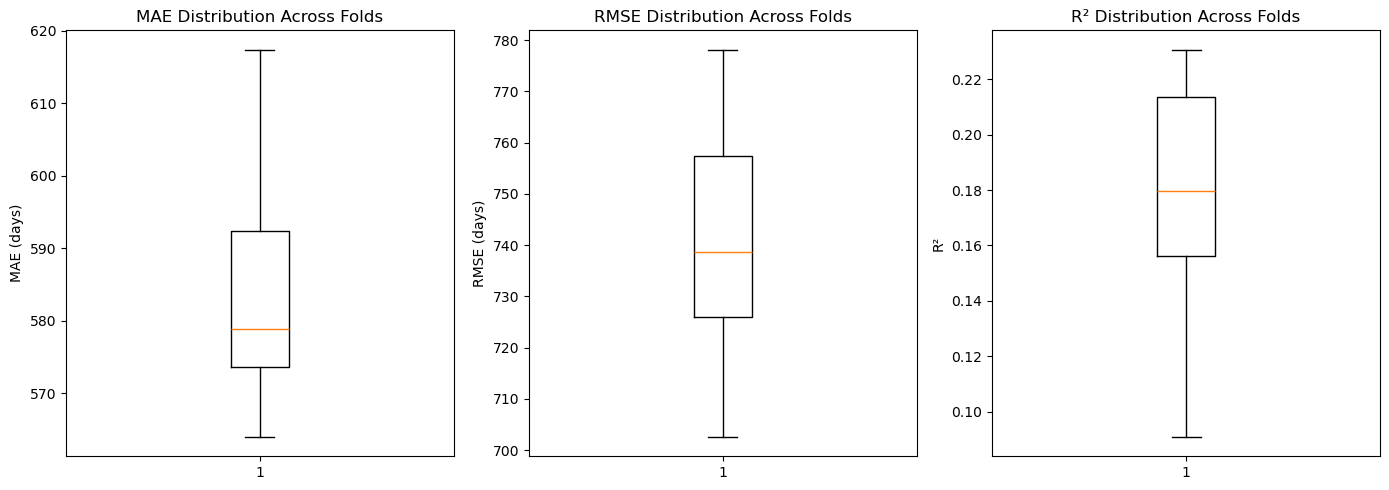

In [38]:
# Cell 11: Per-Fold Metrics Summary
# Calculate metrics per fold from the predictions_df
fold_metrics = []

for (repeat, fold), group in predictions_df.groupby(['repeat', 'fold']):
    y_true = group['actual_time'].values
    y_pred = group['predicted_time'].values
    
    fold_metrics.append({
        'repeat': repeat,
        'fold': fold,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred) if len(y_true) > 1 else np.nan
    })

fold_metrics_df = pd.DataFrame(fold_metrics)

print("=== Per-Fold CV Results ===\n")
print(f"MAE:  {fold_metrics_df['MAE'].mean():.2f} ± {fold_metrics_df['MAE'].std():.2f} days")
print(f"RMSE: {fold_metrics_df['RMSE'].mean():.2f} ± {fold_metrics_df['RMSE'].std():.2f} days")
print(f"R²:   {fold_metrics_df['R2'].mean():.4f} ± {fold_metrics_df['R2'].std():.4f}")

# Boxplot of fold metrics
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].boxplot(fold_metrics_df['MAE'].values)
axes[0].set_ylabel('MAE (days)')
axes[0].set_title('MAE Distribution Across Folds')

axes[1].boxplot(fold_metrics_df['RMSE'].values)
axes[1].set_ylabel('RMSE (days)')
axes[1].set_title('RMSE Distribution Across Folds')

axes[2].boxplot(fold_metrics_df['R2'].values)
axes[2].set_ylabel('R²')
axes[2].set_title('R² Distribution Across Folds')

plt.tight_layout()
plt.show()

In [ ]:
# Cell 13: Save Validation Predictions and Summary
# Save aggregated predictions
results_df_final = pd.DataFrame({
    'sample_idx': agg_predictions['sample_idx'],
    'Actual_Time': y_actual,
    'Predicted_Time': y_pred_val,
    'Residual': residuals_val,
    'Event': event_val
})

results_df_final.to_csv('xgboost_time_validation_predictions.csv', index=False)
print("Validation predictions saved to 'xgboost_time_validation_predictions.csv'")

# Save all fold predictions
predictions_df.to_csv('xgboost_time_all_fold_predictions.csv', index=False)
print("All fold predictions saved to 'xgboost_time_all_fold_predictions.csv'")

# Save model summary
if 'best_model_params' in locals():
    params_str = str(best_model_params)
    params_used = best_model_params
else:
    params_str = str(model_params)
    params_used = model_params

summary = {
    'Model': 'XGBoost Regressor',
    'Model_Params': params_str,
    'n_estimators': params_used.get('n_estimators', 'N/A'),
    'max_depth': params_used.get('max_depth', 'N/A'),
    'learning_rate': params_used.get('learning_rate', 'N/A'),
    'min_child_weight': params_used.get('min_child_weight', 'N/A'),
    'N_Splits': n_splits,
    'N_Repeats': n_repeats,
    'Val_RMSE': val_metrics['RMSE'],
    'Val_MAE': val_metrics['MAE'],
    'Val_MedianAE': val_metrics['MedianAE'],
    'Val_R2': val_metrics['R2'],
    'CV_MAE_Mean': fold_metrics_df['MAE'].mean(),
    'CV_MAE_Std': fold_metrics_df['MAE'].std(),
    'CV_R2_Mean': fold_metrics_df['R2'].mean(),
    'CV_R2_Std': fold_metrics_df['R2'].std()
}

summary_df = pd.DataFrame([summary])
summary_df.to_csv('xgboost_time_summary.csv', index=False)
print("Model summary saved to 'xgboost_time_summary.csv'")

print("\n=== Final Summary ===")
for k, v in summary.items():
    if k not in ['Model_Params']:  # Skip long string
        print(f"  {k}: {v}")

print(f"\nModel trained with optimized parameters from grid search")
print(f"Best parameters: n_estimators={params_used.get('n_estimators')}, max_depth={params_used.get('max_depth')}, learning_rate={params_used.get('learning_rate')}, min_child_weight={params_used.get('min_child_weight')}")


Validation predictions saved to 'xgboost_time_validation_predictions.csv'
All fold predictions saved to 'xgboost_time_all_fold_predictions.csv'
Model summary saved to 'xgboost_time_summary.csv'

=== Final Summary ===
  Model: XGBoost Regressor
  Model_Params: {'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.1, 'min_child_weight': 3, 'random_state': 42, 'n_jobs': -1}
  N_Splits: 4
  N_Repeats: 5
  Val_RMSE: 719.7722830829925
  Val_MAE: 570.1383327330598
  Val_MedianAE: 500.7499694824219
  Val_R2: 0.22507987176888433
  CV_MAE_Mean: 583.3600647179335
  CV_MAE_Std: 15.000063641741146
  CV_R2_Mean: 0.17861473180460755
  CV_R2_Std: 0.03651346367105097
